# Multi-Event Shared-`SubspaceCBM` Pooling Across Holocene Miyake Events

On a single Miyake event (`775CE`), analytically marginalizing a global cosmic-ray Gaussian process (`GaussianField`) collapses single-hemisphere carbon-box identifiability ($d_{\mathrm{eff}} < 1$) while paired Northern and Southern Hemisphere chronologies rescue $3\text{–}4$ collective exchange modes (see Tutorial `06`). Because the physical carbon cycle is shared across Holocene epochs whereas cosmic-ray background realizations $\delta Q_e(t)$, inter-laboratory baseline offsets $\boldsymbol{\delta}_e$, and spike parameters $(t_{0,e}, \tau_e, \Phi_e)$ are conditionally independent across widely separated centuries, pooling multiple Miyake events sums their Schur-marginalized Fisher information matrices linearly:

$$
\widetilde{F}_{\mathrm{tot}} = \sum_{e=1}^{E} \widetilde{F}_e,
\qquad
\ln\mathcal{L}(\boldsymbol{\alpha}, \{\boldsymbol{\psi}_e\}) = \sum_{e=1}^{E} \ln\mathcal{L}_e(\boldsymbol{\alpha}, \boldsymbol{\psi}_e).
$$

Crucially, the shared carbon-box prior $\boldsymbol{\alpha} \sim \mathcal{N}(\mathbf{0}, I_m)$ enters both the pooled Fisher posterior covariance and `multi_event_marginal_log_posterior` **once** (never double-counted across events), while the block-diagonal Woodbury likelihood scales linearly as $\mathcal{O}(\sum_e N_e r_e^2)$.

In [1]:
import gc
import math

import arviz as az
import jax
import jax.numpy as jnp
import matplotlib.pyplot as plt
import numpy as np
import ticktack as tt

cbm0 = tt.load_preset("Brehm21", kind="balanced")
sho_kernel = tt.QuasiPeriodicSpectrum(sigma=0.25, period_yr=11.0, quality=4.0)

EVENT_SPECS = [
    ("775CE", 774.10, 1.20, 6.4),
    ("993CE", 993.05, 0.50, 4.0),
    ("660BCE", -663.30, 1.80, 5.0),
    ("5259BCE", -5258.70, 0.60, 7.2),
]

windows = []
print(f"{'Event':8s} {'Series':>6s} {'Hemispheres':>12s} {'Rings':>6s} {'Span (CE)':>22s} {'n_grid':>7s}")
print("-" * 68)
for name, t_sp, dur, fl in EVENT_SPECS:
    ds = tt.load_bundled_event(name)
    t_lo, t_hi = ds.time_span
    n_grid = max(int(round((t_hi - t_lo) + 15.0)) + 1, 24)
    gf = tt.GaussianField(
        jnp.zeros((n_grid,), dtype=jnp.float64),
        t_start=t_lo - 15.0,
        t_end=t_hi + 0.5,
        kernel=sho_kernel,
    )
    sp = tt.MiyakeSpike(t_start=t_sp, duration=dur, fluence=fl, profile="boxcar")
    prod = tt.ProductionSum(steady=tt.SteadyProduction(), field=gf, spike=sp)
    cfg = tt.LinearMarginalConfig(offset_mode="hierarchical", marginalize_field=True)
    ev = tt.EventWindow(name=name, dataset=ds, production=prod, marginal_config=cfg)
    windows.append(ev)
    hem_str = ",".join(ds.hemispheres)
    print(f"{name:8s} {ds.n_series:6d} {hem_str:>12s} {ds.n_obs:6d} [{t_lo:8.1f}, {t_hi:7.1f}] {n_grid:7d}")

prior_sd = 0.35
fisher_prog = {}
single_fisher = {}
labels_prog = {
    1: "775CE",
    2: "775CE + 993CE",
    3: "+ 660BCE",
    4: "+ 5259BCE",
}

for w in windows:
    single_fisher[w.name] = tt.multi_event_cbm_gp_fisher_spectrum(
        cbm0, tt.MultiEventDataset((w,), name=w.name), prior_sd=prior_sd
    )

print("\nGP-marginalized Brehm21 Fisher progression (prior_sd = 0.35, sho_solar + hierarchical offsets):")
print(f"{'Pooled Subset':32s} {'d_eff':>6s} {'Bits':>6s} {'mu_1':>7s} {'mu_2':>7s} {'mu_3':>7s} {'mu_4':>7s} {'mu_5':>7s} {'mu_6':>7s}")
print("-" * 90)
for k in (1, 2, 3, 4):
    if k == 1:
        res_k = single_fisher[windows[0].name]
    else:
        mds_k = tt.MultiEventDataset(tuple(windows[:k]), name=f"pool_{k}")
        res_k = tt.multi_event_cbm_gp_fisher_spectrum(
            cbm0, mds_k, prior_sd=prior_sd
        )
    fisher_prog[k] = res_k
    mu = [float(v) for v in res_k.eigenvalues[:6]]
    subset_label = " + ".join(w.name for w in windows[:k])
    print(
        f"{subset_label:32s} {float(res_k.d_eff):6.2f} {float(res_k.info_bits):6.2f} "
        f"{mu[0]:7.1f} {mu[1]:7.2f} {mu[2]:7.2f} {mu[3]:7.2f} {mu[4]:7.2f} {mu[5]:7.2f}"
    )

# Fixed 4-event pooled eigenbasis decomposition: mu_k(pool) = sum_e v_{k,pool}^T F_e v_{k,pool}
V_pool = np.asarray(fisher_prog[4].prior_whitened_modes[:, :6])
V_775 = np.asarray(fisher_prog[1].prior_whitened_modes[:, :6])
overlap_mat = np.abs(V_775.T @ V_pool)
rayleigh_by_event = {}
for w in windows:
    F_e = np.asarray(single_fisher[w.name].whitened_fisher)
    rayleigh_by_event[w.name] = np.einsum("ik,ij,jk->k", V_pool, F_e, V_pool)

mu_pool_6 = np.asarray(fisher_prog[4].eigenvalues[:6])
rayleigh_sum = sum(rayleigh_by_event.values())
assert np.allclose(rayleigh_sum, mu_pool_6, rtol=1e-10, atol=1e-10)

print("\nFixed 4-event pooled eigenbasis Rayleigh contributions (exact additivity check):")
print(
    f"{'Mode':6s} {'775CE':>8s} {'993CE':>8s} {'660BCE':>8s} {'5259BCE':>8s} "
    f"{'Pool mu_k':>10s} {'Prec Gain':>10s} {'dInfo(b)':>9s} {'|v1.v4|':>8s}"
)
print("-" * 82)
for i in range(6):
    c1 = float(rayleigh_by_event["775CE"][i])
    c2 = float(rayleigh_by_event["993CE"][i])
    c3 = float(rayleigh_by_event["660BCE"][i])
    c4 = float(rayleigh_by_event["5259BCE"][i])
    mp = float(mu_pool_6[i])
    prec_gain = (1.0 + mp) / (1.0 + c1)
    dinfo_bits = 0.5 * math.log2(prec_gain)
    ov = float(overlap_mat[i, i])
    print(
        f"Mode {i+1:<1d} {c1:8.2f} {c2:8.2f} {c3:8.2f} {c4:8.2f} "
        f"{mp:10.2f} {prec_gain:9.2f}x {dinfo_bits:+9.2f} {ov:8.3f}"
    )


Event    Series  Hemispheres  Rings              Span (CE)  n_grid
--------------------------------------------------------------------
775CE        28  north,south    313 [   760.2,   781.2]      37
993CE         9  north,south     97 [   990.2,  1001.2]      27
660BCE        2        north     58 [  -667.8,  -639.2]      45
5259BCE       4        north     96 [ -5269.8, -5244.2]      41

GP-marginalized Brehm21 Fisher progression (prior_sd = 0.35, sho_solar + hierarchical offsets):
Pooled Subset                     d_eff   Bits    mu_1    mu_2    mu_3    mu_4    mu_5    mu_6
------------------------------------------------------------------------------------------
775CE                              4.02   8.38   198.6   18.85    4.20    1.38    0.57    0.33
775CE + 993CE                      4.29   9.08   253.2   22.66    4.75    1.97    0.78    0.38
775CE + 993CE + 660BCE             4.54   9.54   253.7   22.77    5.21    3.13    1.15    0.39
775CE + 993CE + 660BCE + 5259BCE   4.72 

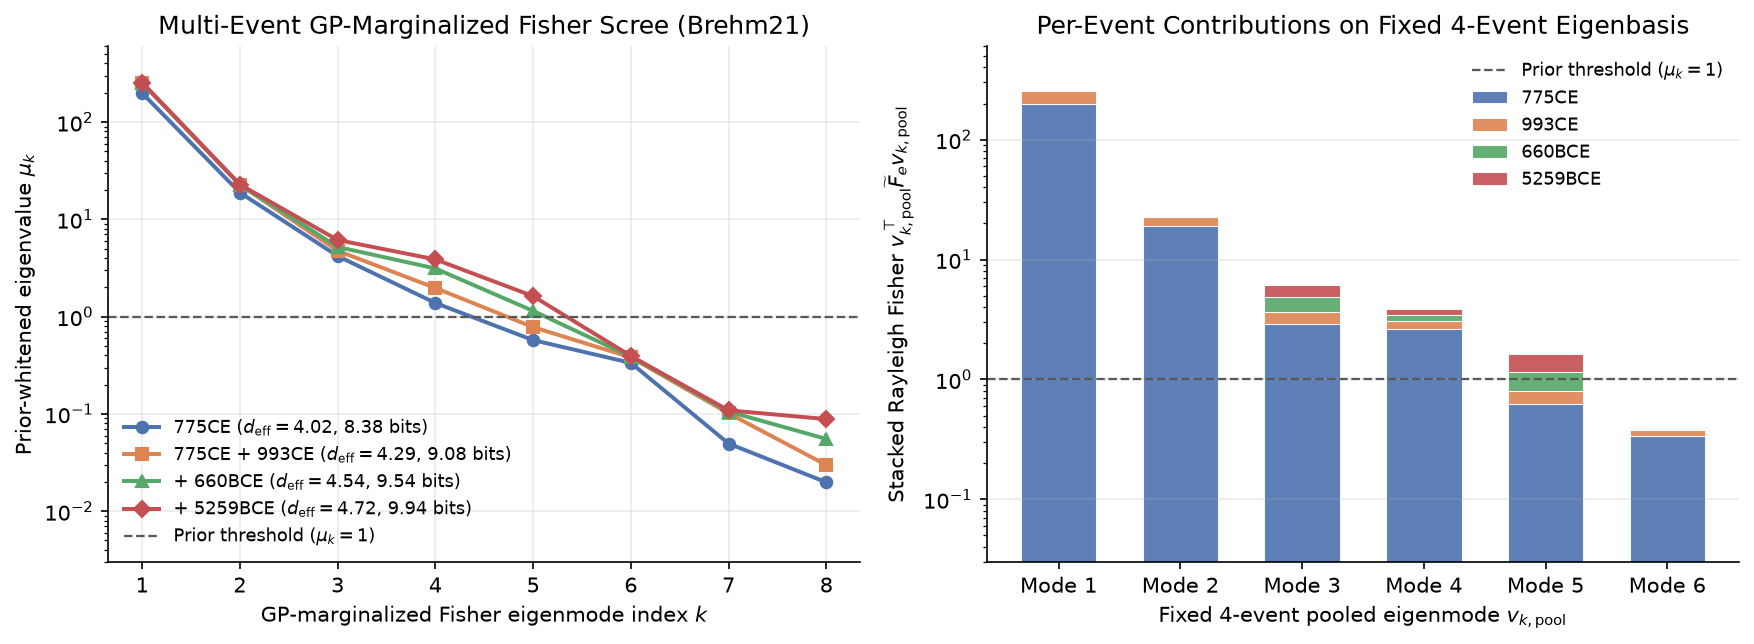

In [2]:
with plt.rc_context({"figure.dpi": 130, "axes.spines.top": False, "axes.spines.right": False}):
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11.8, 4.4))

    colours = {1: "#4c72b0", 2: "#dd8452", 3: "#55a868", 4: "#c44e52"}
    ev_colours = {"775CE": "#4c72b0", "993CE": "#dd8452", "660BCE": "#55a868", "5259BCE": "#c44e52"}
    markers = {1: "o", 2: "s", 3: "^", 4: "D"}
    k_idx = np.arange(1, 9)

    for k in (1, 2, 3, 4):
        ev_arr = np.asarray(fisher_prog[k].eigenvalues[:8])
        lbl = (
            f"{labels_prog[k]} "
            f"($d_{{\\mathrm{{eff}}}}={float(fisher_prog[k].d_eff):.2f}$, "
            f"${float(fisher_prog[k].info_bits):.2f}$ bits)"
        )
        ax1.semilogy(
            k_idx,
            np.maximum(ev_arr, 1e-4),
            marker=markers[k],
            color=colours[k],
            linewidth=1.9,
            markersize=5.5,
            label=lbl,
        )

    ax1.axhline(1.0, color="0.35", linestyle="--", linewidth=1.1, label=r"Prior threshold ($\mu_k = 1$)")
    ax1.set_xticks(k_idx)
    ax1.set_xlabel("GP-marginalized Fisher eigenmode index $k$")
    ax1.set_ylabel(r"Prior-whitened eigenvalue $\mu_k$")
    ax1.set_title("Multi-Event GP-Marginalized Fisher Scree (Brehm21)")
    ax1.set_ylim(3e-3, 6e2)
    ax1.grid(True, which="major", alpha=0.25)
    ax1.legend(frameon=False, fontsize=8.5, loc="lower left")

    # Right panel: stacked per-event Rayleigh contributions on the fixed 4-event pooled eigenbasis
    modes_bar = np.arange(1, 7)
    bottom = np.zeros(6, dtype=np.float64)
    for ev_name in ("775CE", "993CE", "660BCE", "5259BCE"):
        contrib = np.maximum(rayleigh_by_event[ev_name], 0.0)
        ax2.bar(
            modes_bar,
            contrib,
            bottom=bottom,
            width=0.62,
            color=ev_colours[ev_name],
            alpha=0.90,
            edgecolor="white",
            linewidth=0.5,
            label=ev_name,
        )
        bottom = bottom + contrib

    ax2.set_yscale("log")
    ax2.set_ylim(0.03, 6e2)
    ax2.axhline(1.0, color="0.35", linestyle="--", linewidth=1.1, label=r"Prior threshold ($\mu_k = 1$)")
    ax2.set_xticks(modes_bar)
    ax2.set_xticklabels([f"Mode {i}" for i in modes_bar])
    ax2.set_xlabel(r"Fixed 4-event pooled eigenmode $v_{k,\mathrm{pool}}$")
    ax2.set_ylabel(r"Stacked Rayleigh Fisher $v_{k,\mathrm{pool}}^\top \widetilde{F}_e v_{k,\mathrm{pool}}$")
    ax2.set_title("Per-Event Contributions on Fixed 4-Event Eigenbasis")
    ax2.grid(True, axis="y", which="major", alpha=0.25)
    ax2.legend(frameon=False, fontsize=8.5, loc="upper right")

    fig.tight_layout()
    plt.show()

jax.clear_caches()
gc.collect()


Two distinct physical mechanisms appear on the fixed 4-event pooled eigenbasis above:

1. Adding the two-hemisphere `993CE` compilation (`9` NH + SH series) strengthens the antisymmetric stratosphere–troposphere / inter-hemispheric modes ($|v_{1}\cdot v_{4}| = 1.000$: Mode 1 posterior precision $1.28\times$, $+0.18\text{ bits}$; Mode 2 posterior precision $1.20\times$, $+0.13\text{ bits}$) while contributing across the symmetric modes.
2. Adding the Northern-Hemisphere-only `660BCE` and `5259BCE` compilations leaves antisymmetric Modes 1–2 nearly unchanged ($\le 0.54$ Rayleigh Fisher each) while stacking directly onto the symmetric biosphere/ocean modes — boosting Mode 3 posterior precision by $1.83\times$ ($+0.44\text{ bits}$), lifting Mode 5 cleanly across the prior threshold ($0.62 \to 1.62$, posterior precision $1.62\times$, $+0.35\text{ bits}$), and raising total constrained dimensionality from $d_{\mathrm{eff}} = 4.02$ ($8.38\text{ bits}$) to $4.72$ ($9.94\text{ bits}$).

Next, we jointly fit the two two-hemisphere compilations (`775CE + 993CE`, `410` total tree-ring measurements) under a shared `SubspaceCBM(m = 3)` with independent per-event `MiyakeSpike` pulses, hierarchical laboratory offsets, and marginalized `sho_solar` `GaussianField` backgrounds using `fit_multi_event_subspace_cbm(..., reweight_exact=True)`.

In [3]:
mds_2 = tt.MultiEventDataset((windows[0], windows[1]), name="775CE_993CE")
cbm_sub3 = tt.SubspaceCBM.from_fisher(cbm0, fisher_prog[2], n_modes=3)

# Single-event 775CE Laplace reference on the identical 3-mode basis
mds_1 = tt.MultiEventDataset((windows[0],), name="775CE_only")
model_1 = tt.MultiEventModel.from_multi_dataset(cbm_sub3, mds_1)
ps_1 = tt.ParameterSpace(
    model_1,
    [
        tt.ParamSpec("cbm.alpha", "identity", prior_mean=0.0, prior_sd=1.0),
        tt.ParamSpec("events.775CE.spike.t_start", "identity", prior_mean=774.2, prior_sd=1.5),
        tt.ParamSpec("events.775CE.spike.duration", "sigmoid", prior_mean=-0.3, prior_sd=1.4, low=0.05, high=2.5),
        tt.ParamSpec("events.775CE.spike.fluence", "exp", prior_mean=math.log(6.4), prior_sd=0.8),
    ],
)
fit_1_lap = tt.fit_multi_event_subspace_cbm(
    model_1, mds_1, ps_1, sampler="laplace", compute_linear_posterior=False
)

# Joint 775CE + 993CE MAP + MAP-centred LinearizedDCTOperator NUTS + exact IS reweighting
model_2 = tt.MultiEventModel.from_multi_dataset(cbm_sub3, mds_2)
ps_2 = tt.ParameterSpace(
    model_2,
    [
        tt.ParamSpec("cbm.alpha", "identity", prior_mean=0.0, prior_sd=1.0),
        tt.ParamSpec("events.775CE.spike.t_start", "identity", prior_mean=774.2, prior_sd=1.5),
        tt.ParamSpec("events.775CE.spike.duration", "sigmoid", prior_mean=-0.3, prior_sd=1.4, low=0.05, high=2.5),
        tt.ParamSpec("events.775CE.spike.fluence", "exp", prior_mean=math.log(6.4), prior_sd=0.8),
        tt.ParamSpec("events.993CE.spike.t_start", "identity", prior_mean=993.1, prior_sd=1.5),
        tt.ParamSpec("events.993CE.spike.duration", "sigmoid", prior_mean=-0.5, prior_sd=1.4, low=0.05, high=2.5),
        tt.ParamSpec("events.993CE.spike.fluence", "exp", prior_mean=math.log(4.0), prior_sd=0.8),
    ],
)

fit_joint = tt.fit_multi_event_subspace_cbm(
    model_2,
    mds_2,
    ps_2,
    sampler="nuts",
    reweight_exact=True,
    use_linearized_dct=True,
    is_max_draws=None,
    num_warmup=150,
    num_samples=250,
    num_chains=2,
    max_tree_depth=8,
    rng_key=jax.random.PRNGKey(2026),
)

def _weighted_mean_sd(x, w):
    mean = np.sum(w * x, axis=0)
    var = np.sum(w * np.square(x - mean), axis=0)
    return mean, np.sqrt(np.maximum(var, 0.0))

diag = fit_joint.diagnostics
w_is = np.asarray(fit_joint.weights_is, dtype=np.float64)
sd_lap_1 = np.sqrt(np.diag(np.asarray(fit_1_lap.laplace_cov))[:3])
sd_lap_2 = np.sqrt(np.diag(np.asarray(fit_joint.laplace_cov))[:3])
alpha_draws = np.asarray(fit_joint.idata.posterior["cbm__alpha"]).reshape(-1, 3)
alpha_mean, alpha_sd = _weighted_mean_sd(alpha_draws, w_is[:, None])

print(f"MAP converged: {fit_joint.map_converged} ({fit_joint.map_steps} L-BFGS-B steps)")
print(
    f"NUTS: {diag['n_divergences']} divergences, {diag['n_max_treedepth']} max-treedepth hits, "
    f"mean accept = {diag['mean_accept_prob']:.3f}, "
    f"max R-hat = {diag['max_rhat']:.3f}, min ESS_bulk = {diag['min_ess_bulk']:.0f}"
)
print(
    f"Exact IS check ({diag['n_eval']}/{diag['n_total']} draws): "
    f"Kish ESS / S = {fit_joint.kish_ess_ratio:.4f}, "
    f"median |dlnL| = {fit_joint.median_abs_dlnL:.4f} nats, "
    f"max |dlnL| = {fit_joint.max_abs_dlnL:.3f} nats"
)
print(
    f"Raw chi2 / N (unrescaled sigma): "
    f"775CE = {diag['per_event_chi2_per_n']['775CE']:.3f} (N={windows[0].n_obs}), "
    f"993CE = {diag['per_event_chi2_per_n']['993CE']:.3f} (N={windows[1].n_obs})"
)
print("\nShared SubspaceCBM(m=3) IS-weighted mode posteriors:")
print(f"{'Mode':8s} {'775CE-only SD':>14s} {'Joint Laplace SD':>17s} {'IS-NUTS Mean +/- SD':>21s} {'Contraction':>12s}")
for i in range(3):
    contr = 1.0 - alpha_sd[i] ** 2
    print(
        f"alpha_{i+1:<2d} {sd_lap_1[i]:14.3f} {sd_lap_2[i]:17.3f} "
        f"{alpha_mean[i]:+9.3f} +/- {alpha_sd[i]:.3f} {contr:13.2f}"
    )

print("\nPer-event MiyakeSpike IS-weighted NUTS posteriors (physical fluence & q0-yr conventions):")
for ev_name in ("775CE", "993CE"):
    ts = np.asarray(fit_joint.idata.posterior[f"events__{ev_name}__spike__t_start"]).reshape(-1)
    du = np.asarray(fit_joint.idata.posterior[f"events__{ev_name}__spike__duration"]).reshape(-1)
    fl = np.asarray(fit_joint.idata.posterior[f"events__{ev_name}__spike__fluence"]).reshape(-1)
    g_off = float(fit_joint.event_linear_posteriors[ev_name].offset_global_mean)
    fl_atoms = np.asarray(tt.RadiocarbonModel.fluence_atoms_cm2(fl), dtype=np.float64)
    yq0_pi = np.asarray(tt.RadiocarbonModel.fluence_q0_years(fl), dtype=np.float64)
    yq0_loc = np.asarray(
        tt.RadiocarbonModel.fluence_q0_years(fl, baseline_d14c_permil=g_off), dtype=np.float64
    )
    ts_m, ts_s = _weighted_mean_sd(ts, w_is)
    du_m, du_s = _weighted_mean_sd(du, w_is)
    fa_m, fa_s = _weighted_mean_sd(fl_atoms / 1e8, w_is)
    ypi_m, ypi_s = _weighted_mean_sd(yq0_pi, w_is)
    yloc_m, yloc_s = _weighted_mean_sd(yq0_loc, w_is)
    print(
        f"{ev_name:6s}: t_start = {ts_m:.2f} +/- {ts_s:.2f} CE | "
        f"dur = {du_m:.2f} +/- {du_s:.2f} yr | "
        f"Phi = ({fa_m:.2f} +/- {fa_s:.2f})e8 atoms/cm^2 | "
        f"Q/q0_PI = {ypi_m:.2f} +/- {ypi_s:.2f} yr | "
        f"Q/q0_local(Delta0={g_off:+.1f}‰) = {yloc_m:.2f} +/- {yloc_s:.2f} yr"
    )


MAP converged: True (36 L-BFGS-B steps)
NUTS: 0 divergences, 0 max-treedepth hits, mean accept = 0.931, max R-hat = 1.022, min ESS_bulk = 145
Exact IS check (500/500 draws): Kish ESS / S = 0.9985, median |dlnL| = 0.0055 nats, max |dlnL| = 0.367 nats
Raw chi2 / N (unrescaled sigma): 775CE = 0.967 (N=313), 993CE = 1.124 (N=97)

Shared SubspaceCBM(m=3) IS-weighted mode posteriors:
Mode      775CE-only SD  Joint Laplace SD   IS-NUTS Mean +/- SD  Contraction
alpha_1           0.101             0.088    -0.137 +/- 0.089          0.99
alpha_2           0.270             0.251    -0.533 +/- 0.265          0.93
alpha_3           0.498             0.479    +1.332 +/- 0.524          0.73

Per-event MiyakeSpike IS-weighted NUTS posteriors (physical fluence & q0-yr conventions):
775CE : t_start = 773.98 +/- 0.16 CE | dur = 1.37 +/- 0.32 yr | Phi = (2.50 +/- 0.29)e8 atoms/cm^2 | Q/q0_PI = 4.50 +/- 0.53 yr | Q/q0_local(Delta0=-21.8‰) = 4.60 +/- 0.54 yr
993CE : t_start = 993.01 +/- 0.15 CE | dur = 0.4

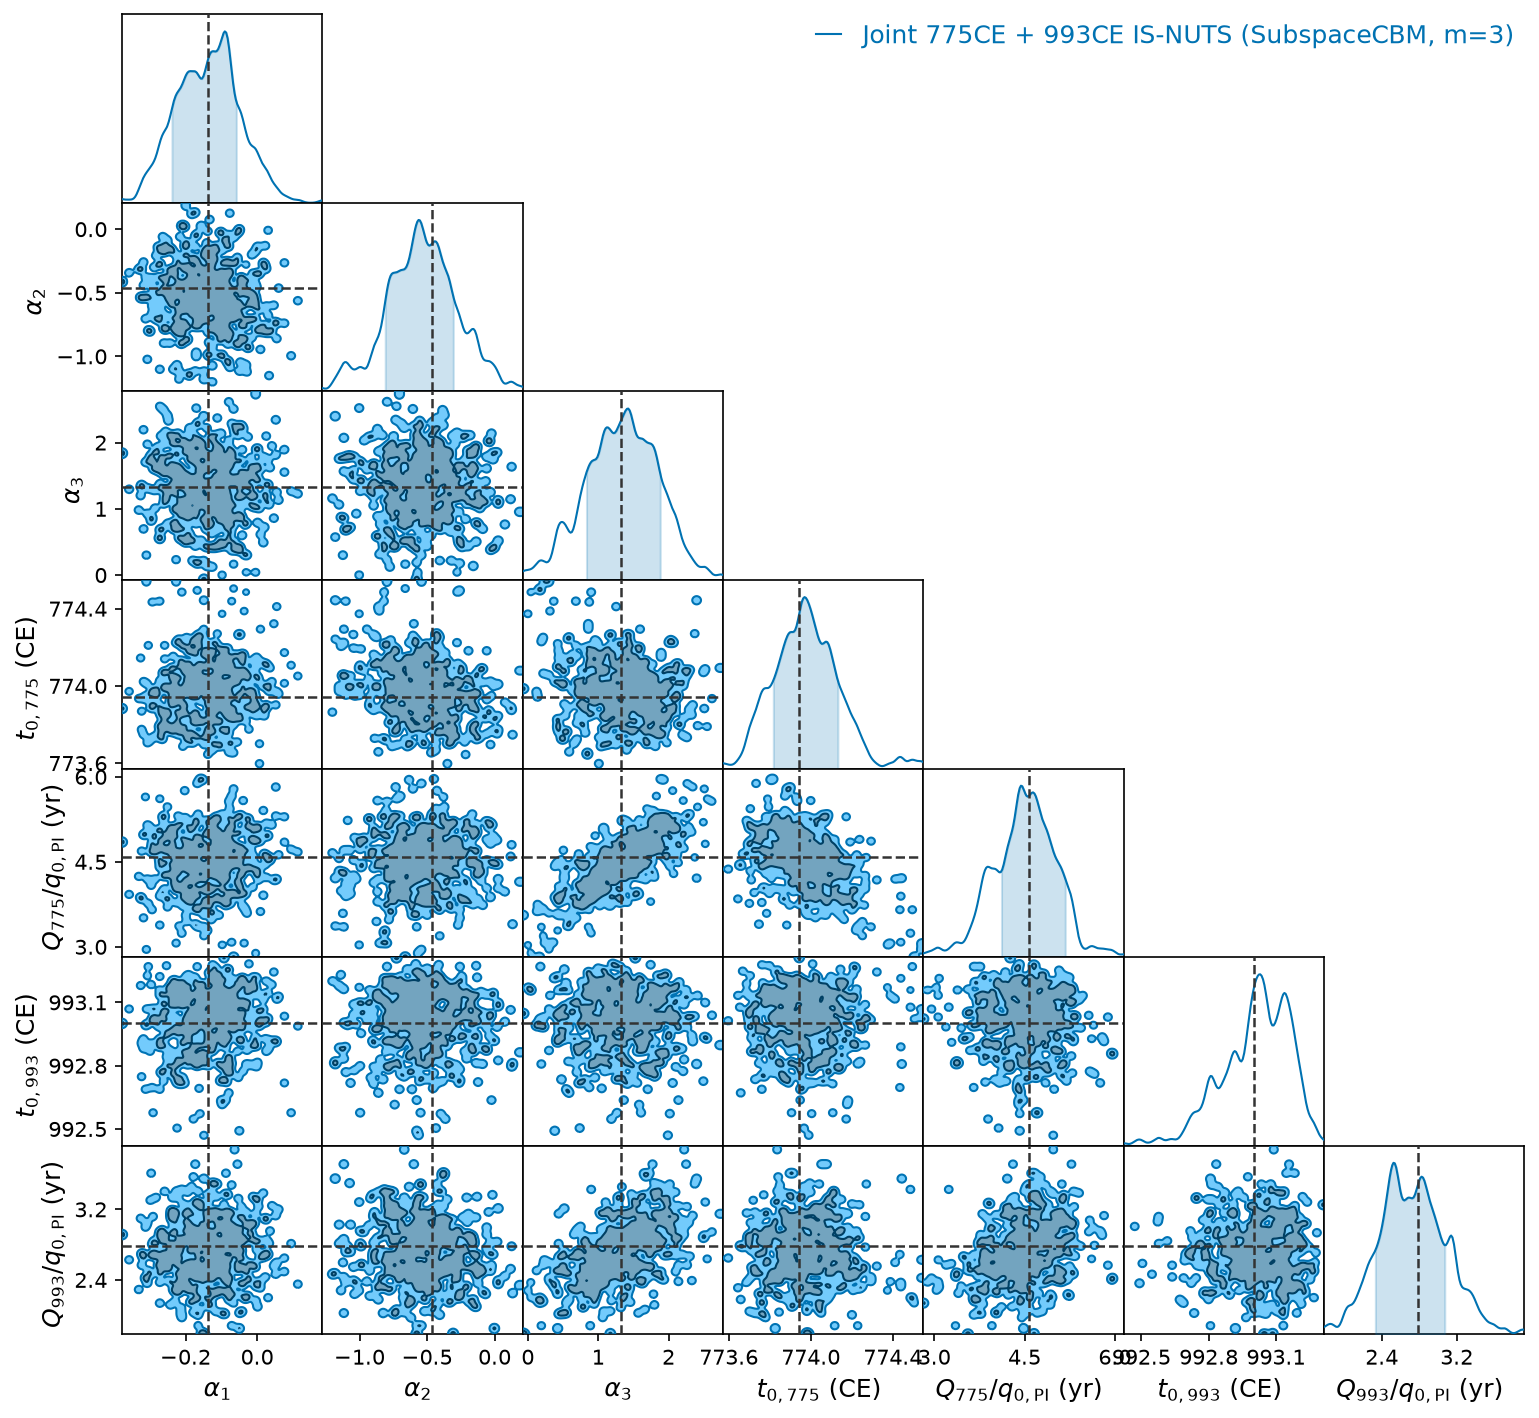

In [4]:
post = fit_joint.idata.posterior
a_ch = np.asarray(post["cbm__alpha"])  # (C, S, 3)

corner_idata = az.from_dict(
    {
        "posterior": {
            "alpha_1": a_ch[:, :, 0],
            "alpha_2": a_ch[:, :, 1],
            "alpha_3": a_ch[:, :, 2],
            "t_775": np.asarray(post["events__775CE__spike__t_start"]),
            "Q_775": np.asarray(tt.RadiocarbonModel.fluence_q0_years(post["events__775CE__spike__fluence"])),
            "t_993": np.asarray(post["events__993CE__spike__t_start"]),
            "Q_993": np.asarray(tt.RadiocarbonModel.fluence_q0_years(post["events__993CE__spike__fluence"])),
        }
    }
)

a_map = np.asarray(fit_joint.theta_map["cbm.alpha"])
map_truth = {
    "alpha_1": float(a_map[0]),
    "alpha_2": float(a_map[1]),
    "alpha_3": float(a_map[2]),
    "t_775": float(fit_joint.theta_map["events.775CE.spike.t_start"]),
    "Q_775": float(tt.RadiocarbonModel.fluence_q0_years(fit_joint.theta_map["events.775CE.spike.fluence"])),
    "t_993": float(fit_joint.theta_map["events.993CE.spike.t_start"]),
    "Q_993": float(tt.RadiocarbonModel.fluence_q0_years(fit_joint.theta_map["events.993CE.spike.fluence"])),
}

with plt.rc_context({"figure.dpi": 130}):
    fig, _axes = tt.plot_corner(
        corner_idata,
        weights=np.asarray(fit_joint.weights_is, dtype=np.float64),
        param_names={
            "alpha_1": r"$\alpha_1$",
            "alpha_2": r"$\alpha_2$",
            "alpha_3": r"$\alpha_3$",
            "t_775": r"$t_{0,\mathrm{775}}$ (CE)",
            "Q_775": r"$Q_{\mathrm{775}}/q_{0,\mathrm{PI}}$ (yr)",
            "t_993": r"$t_{0,\mathrm{993}}$ (CE)",
            "Q_993": r"$Q_{\mathrm{993}}/q_{0,\mathrm{PI}}$ (yr)",
        },
        truth=map_truth,
        truth_name="Joint exact MAP",
        name="Joint 775CE + 993CE IS-NUTS (SubspaceCBM, m=3)",
        figsize=(11.0, 11.0),
        plot_kwargs={"max_ticks": 3},
    )
    plt.show()


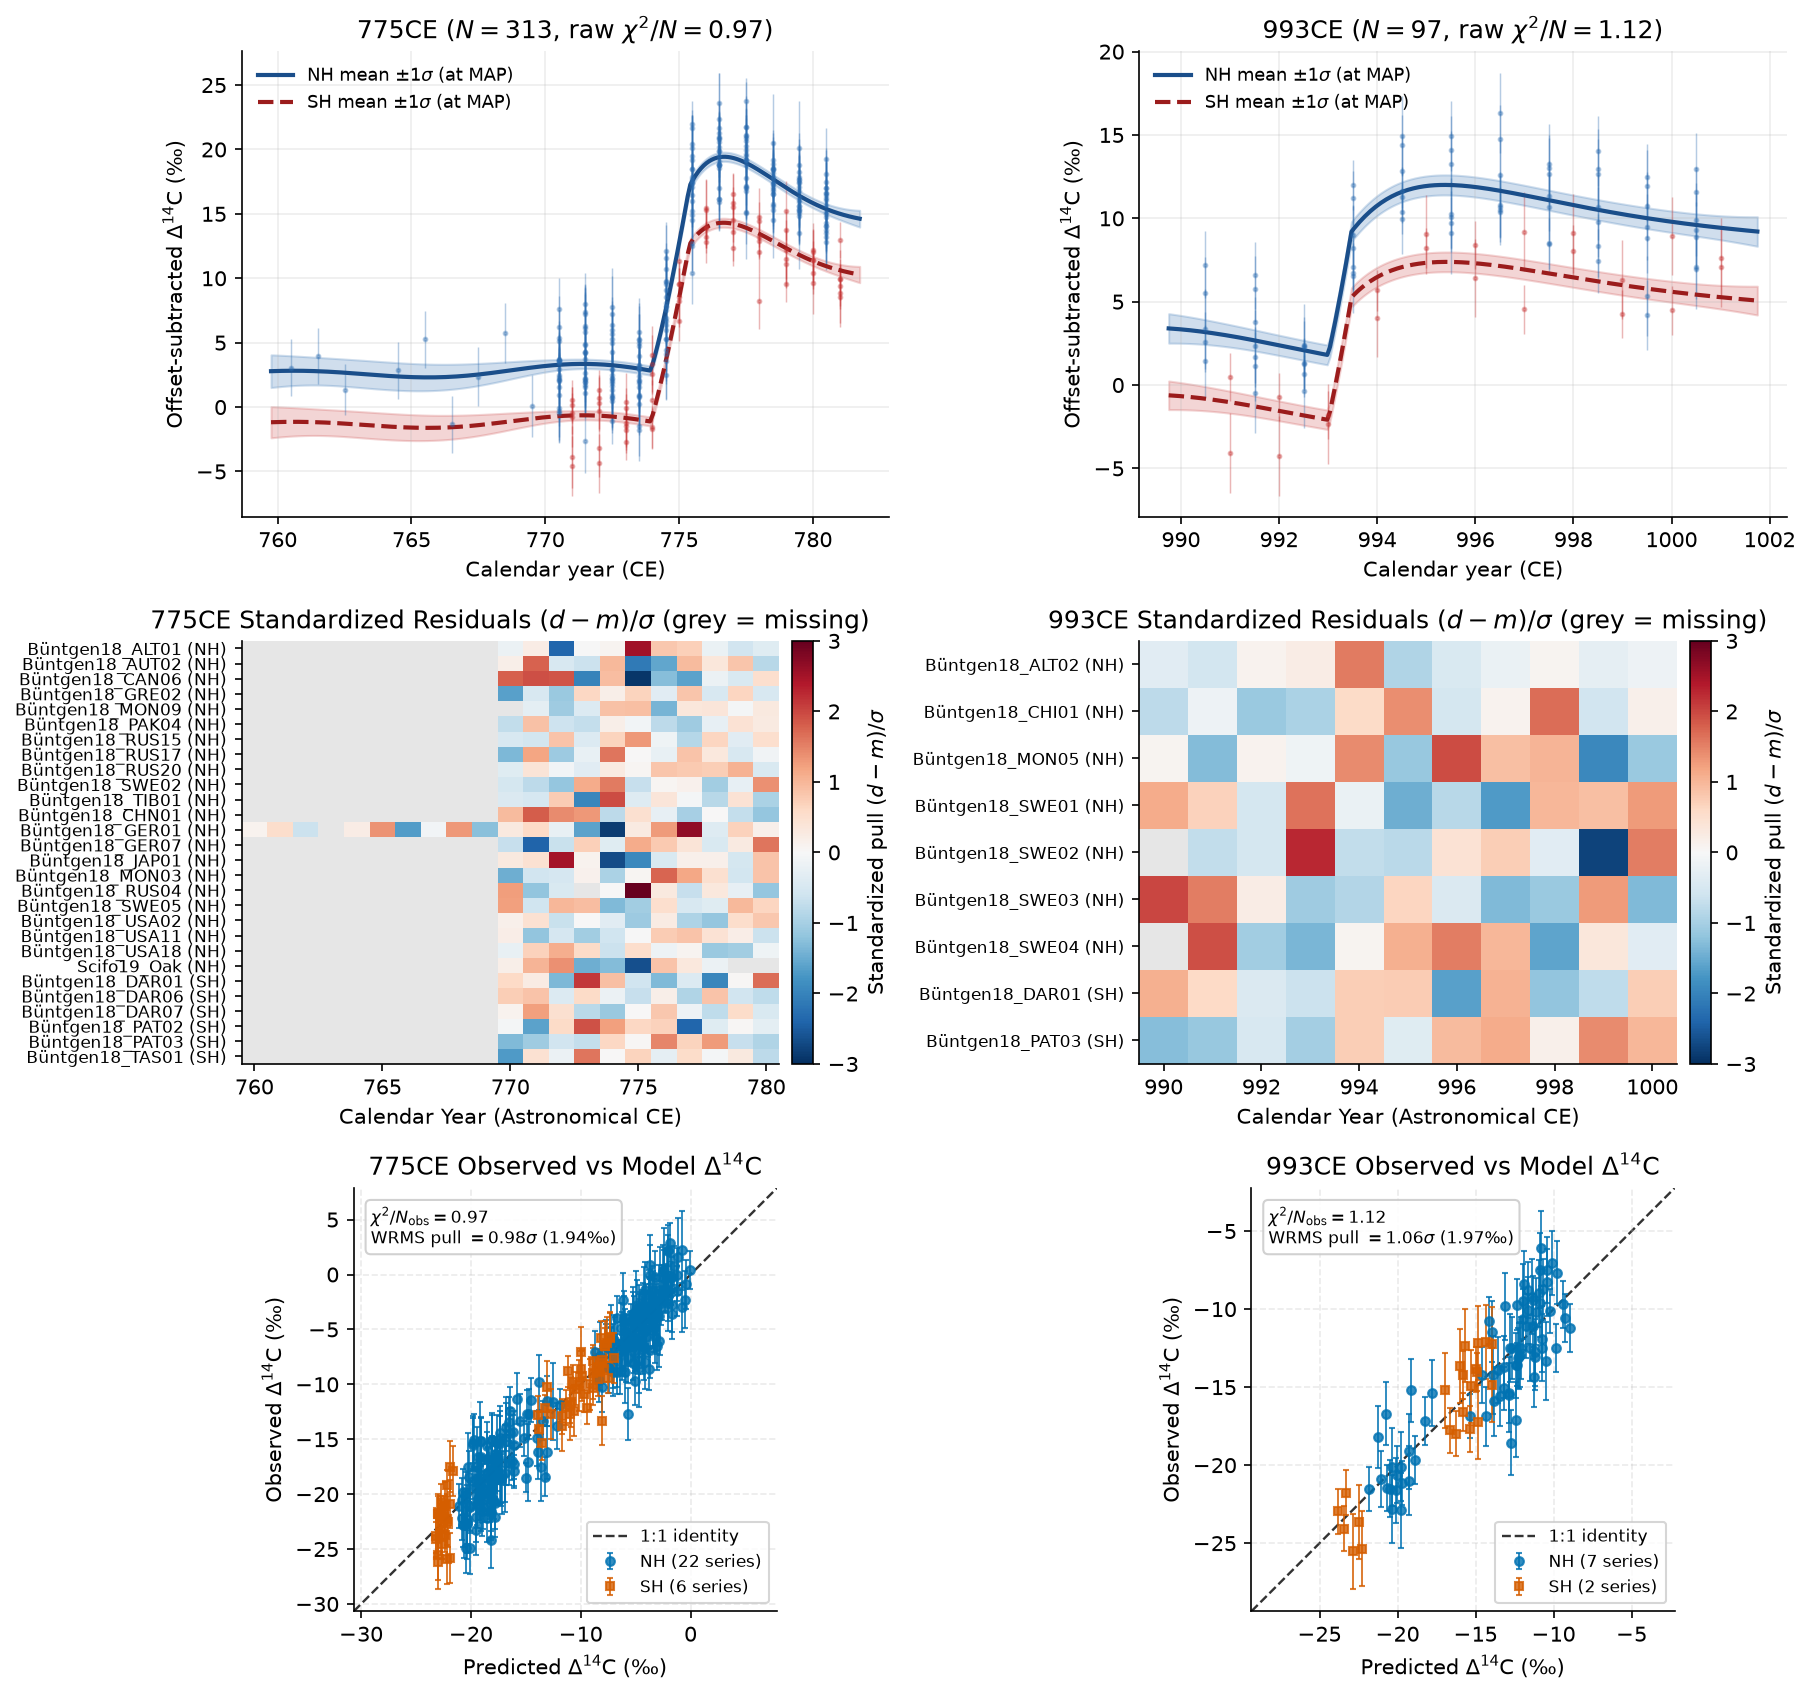

In [5]:
with plt.rc_context({"figure.dpi": 130, "axes.spines.top": False, "axes.spines.right": False}):
    fig, axes = plt.subplots(
        3,
        2,
        figsize=(12.2, 11.4),
        gridspec_kw={"height_ratios": [1.1, 1.0, 1.0]},
    )

    for col_i, ev in enumerate(mds_2.events):
        ds = ev.dataset
        t_lo, t_hi = ds.time_span
        t_fine = jnp.linspace(t_lo - 0.5, t_hi + 0.5, 220)
        m_ev = fit_joint.model.event_model(ev.name)
        lp_nh = tt.linear_posterior(m_ev, ds, ev.marginal_config, t_fine=t_fine, hemisphere="north")
        lp_sh = tt.linear_posterior(m_ev, ds, ev.marginal_config, t_fine=t_fine, hemisphere="south")
        g_off = float(lp_nh.offset_global_mean)
        lab_offs = np.asarray(lp_nh.offset_lab_means)
        chi2_n = fit_joint.diagnostics["per_event_chi2_per_n"][ev.name]

        ax_top = axes[0, col_i]
        ax_mid = axes[1, col_i]
        ax_bot = axes[2, col_i]

        # Row 0: offset-subtracted NH & SH observations vs conditional posterior mean +/- 1 sigma (at MAP)
        for s_idx, s in enumerate(ds.series):
            t_mid = 0.5 * (np.asarray(s.t_starts) + np.asarray(s.t_ends))
            y_corr = np.asarray(s.d14c) - g_off - lab_offs[s_idx]
            sig = np.asarray(s.sigma_d14c)
            c = "#2b6cb0" if s.hemisphere == "north" else "#c53030"
            ax_top.errorbar(
                t_mid, y_corr, yerr=sig, fmt=".", color=c, alpha=0.35, markersize=3.5, elinewidth=0.7
            )

        tf_np = np.asarray(t_fine)
        nh_m = np.asarray(lp_nh.d14c_fine_mean) - g_off
        nh_s = np.asarray(lp_nh.d14c_fine_std)
        sh_m = np.asarray(lp_sh.d14c_fine_mean) - g_off
        sh_s = np.asarray(lp_sh.d14c_fine_std)

        ax_top.plot(tf_np, nh_m, color="#1a4e8a", linewidth=2.0, label=r"NH mean $\pm 1\sigma$ (at MAP)")
        ax_top.fill_between(tf_np, nh_m - nh_s, nh_m + nh_s, color="#2b6cb0", alpha=0.22)
        ax_top.plot(tf_np, sh_m, color="#9b1c1c", linewidth=2.0, linestyle="--", label=r"SH mean $\pm 1\sigma$ (at MAP)")
        ax_top.fill_between(tf_np, sh_m - sh_s, sh_m + sh_s, color="#c53030", alpha=0.20)
        ax_top.set_xlabel("Calendar year (CE)")
        ax_top.set_ylabel(r"Offset-subtracted $\Delta^{14}\mathrm{C}$ (‰)")
        ax_top.set_title(f"{ev.name} ($N = {ev.n_obs}$, raw $\\chi^2 / N = {chi2_n:.2f}$)")
        ax_top.grid(True, alpha=0.22)
        ax_top.legend(frameon=False, fontsize=8.5, loc="upper left")

        # Row 1: audited Schulman-aligned standardized residual heatmap via tt.plot_residual_map
        tt.plot_residual_map(
            ds,
            lp_nh.ring_pred_mean,
            zscore=True,
            title=f"{ev.name} Standardized Residuals $(d - m) / \\sigma$ (grey = missing)",
            ax=ax_mid,
        )

        # Row 2: 1:1 observed vs model-predicted Delta14C correlation diagnostic
        tt.plot_data_model_correlation(
            ds,
            lp_nh.ring_pred_mean,
            title=f"{ev.name} Observed vs Model $\\Delta^{{14}}\\mathrm{{C}}$",
            ax=ax_bot,
        )

    fig.tight_layout()
    plt.show()


## Summary

- **Multi-event Fisher additivity (fixed 4-event eigenbasis)**: Pooling `775CE + 993CE + 660BCE + 5259BCE` lifts GP-marginalized `Brehm21` identifiability (including Slepian–Bangs covariance-sensitivity Fisher rows) from $d_{\mathrm{eff}} = 4.02$ ($8.38\text{ bits}$) to $d_{\mathrm{eff}} = 4.72$ ($9.94\text{ bits}$), boosting Mode 3 posterior precision by $1.83\times$ ($+0.44\text{ bits}$) and lifting Mode 5 across the prior threshold ($0.62 \to 1.62$, posterior precision $1.62\times$, $+0.35\text{ bits}$).
- **Joint `775CE + 993CE` `SubspaceCBM(m = 3)` IS-NUTS inference**: Both events are fitted simultaneously with raw unrescaled $\chi^2 / N = 0.97$ (`775CE`, $N = 313$) and $1.12$ (`993CE`, $N = 97$), `0` divergences, `max R-hat = 1.02`, `min ESS_bulk = 145`, and exact multi-event importance-sampling efficiency $\mathrm{ESS}_{\mathrm{IS}} / S = 0.999$ across all `500/500` draws (`median |Δln L| = 0.0055 nats`).
- **Physical interpretation & yields**: The exact IS-weighted NH + SH posterior remains consistent with nominal `Brehm21` on Mode 1 ($\alpha_1 = -0.14 \pm 0.09$), shows a mild inter-hemispheric shift ($\alpha_2 = -0.53 \pm 0.27$), and prefers a coherent $+2.5\sigma$ symmetric uptake/retention adjustment ($\alpha_3 = +1.33 \pm 0.52$), yielding physical fluences $(2.50 \pm 0.29) \times 10^8\text{ atoms cm}^{-2}$ (`775CE`, $4.50 \pm 0.53\text{ pre-industrial } q_0\text{-yr}$) and $(1.52 \pm 0.20) \times 10^8\text{ atoms cm}^{-2}$ (`993CE`, $2.73 \pm 0.36\text{ pre-industrial } q_0\text{-yr}$).